In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timedelta
import os
import ast
import json
from sqlalchemy import create_engine
from sqlalchemy import text
import urllib

In [ ]:
fumb_test = pd.read_csv("test_data.csv")  

### Data Exploration & Preparation

In [3]:
fumb_test.head()

,user_id,exp_variant,platform,country,client_version,event_timestamp,event_date,event_name,session_number,playtime_cuml,mission_type,mission_index,ilrd_usd,earnings_usd,value_usd
0,0095a37a9239b39128d9d725c7725afb,2,ANDROID,United States,2.6.9,1741027883619546,20250303,focus_lost,1.0,383.0,NaN,NaN,NaN,NaN,NaN
1,0095a37a9239b39128d9d725c7725afb,2,ANDROID,United States,2.6.9,1741027842350541,20250303,mission_complete,1.0,342.0,UnlockCoins,0.0,NaN,NaN,NaN
2,02357ad9490b4da2d579f75a7dbf7466,1,ANDROID,United States,2.6.9,1741041035337888,20250303,focus_lost,1.0,559.0,NaN,NaN,NaN,NaN,NaN
3,02357ad9490b4da2d579f75a7dbf7466,1,ANDROID,United States,2.6.9,1741041920654203,20250303,focus_lost,1.0,636.0,NaN,NaN,NaN,NaN,NaN
4,02357ad9490b4da2d579f75a7dbf7466,1,ANDROID,United States,2.6.9,1741040381971515,20250303,focus_lost,1.0,48.0,NaN,NaN,NaN,NaN,NaN


In [27]:
fumb_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 280588 entries, 0 to 281294
Data columns (total 16 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   user_id          280588 non-null  object             
 1   exp_variant      280588 non-null  int64              
 2   platform         280588 non-null  object             
 3   country          280588 non-null  object             
 4   client_version   280588 non-null  object             
 5   event_timestamp  280588 non-null  datetime64[ns, UTC]
 6   event_date       280588 non-null  datetime64[ns]     
 7   event_name       280588 non-null  object             
 8   session_number   280588 non-null  float64            
 9   playtime_cuml    263710 non-null  float64            
 10  mission_type     36294 non-null   object             
 11  mission_index    36294 non-null   float64            
 12  ilrd_usd         98832 non-null   float64            
 13  earn

In [5]:
fumb_test.describe()

,exp_variant,event_timestamp,event_date,session_number,playtime_cuml,mission_index,ilrd_usd,earnings_usd,value_usd
count,281295.000000,2.812950e+05,2.812950e+05,281294.000000,2.643590e+05,36397.000000,9.908100e+04,2767.000000,271.000000
mean,1.083137,1.741525e+15,2.025031e+07,15.091683,5.184346e+04,241.058109,4.686226e-02,0.065900,7.023035
std,0.819140,3.517879e+11,4.075980e+00,17.425107,1.606092e+05,631.747065,1.049853e-01,0.090529,3.519932
min,0.000000,1.741026e+15,2.025030e+07,1.000000,0.000000e+00,0.000000,4.160125e-07,0.000788,1.990000
25%,0.000000,1.741232e+15,2.025031e+07,3.000000,3.814000e+03,10.000000,8.624261e-03,0.008677,5.990000
50%,1.000000,1.741447e+15,2.025031e+07,8.000000,1.449900e+04,43.000000,2.101531e-02,0.022701,5.990000
75%,2.000000,1.741784e+15,2.025031e+07,21.000000,4.113100e+04,147.000000,5.003700e-02,0.074724,6.490000
max,2.000000,1.742339e+15,2.025032e+07,138.000000,4.709998e+06,7891.000000,4.998889e+00,0.311063,19.990000


In [6]:
fumb_test.shape

(281295, 15)

In [7]:
fumb_test['event_date'].unique()

array([20250303, 20250304, 20250305, 20250306, 20250307, 20250308,
       20250309, 20250310, 20250311, 20250312, 20250313, 20250314,
       20250315, 20250316, 20250317, 20250318])

Remove duplicates

**Essential to be done before parsing event_params_column**

In [8]:
fumb_test.drop_duplicates(inplace=True)

In [9]:
fumb_test.shape

(280589, 15)

extract parameters from event_params

**NO need for this step anymore as its done previously with converting json into csv**

found only one row with null 'session_number' value so removed

In [10]:
fumb_test.dropna(subset=['session_number'], inplace=True)

Upload data to sql

**NO need for this step as there is no database or modelling needed for this task but should be done in usual work enviroment**

convert timestamp column into datetime format

In [11]:
fumb_test['event_timestamp'] = pd.to_datetime(fumb_test['event_timestamp'] / 1_000_000, unit='s')
## micro_seconds

In [12]:
fumb_test['event_timestamp'] = pd.to_datetime(fumb_test['event_timestamp'], errors='coerce', utc=True)

Convert event_date into date format

In [13]:
fumb_test['event_date'] = pd.to_datetime(fumb_test['event_date'], format='%Y%m%d', errors='coerce', utc=True)
fumb_test['event_date'] = fumb_test['event_date'].dt.normalize()

In [14]:
fumb_test['event_date'] = pd.to_datetime(fumb_test['event_date']).dt.tz_localize(None)

In [15]:
fumb_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 280588 entries, 0 to 281294
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   user_id          280588 non-null  object             
 1   exp_variant      280588 non-null  int64              
 2   platform         280588 non-null  object             
 3   country          280588 non-null  object             
 4   client_version   280588 non-null  object             
 5   event_timestamp  280588 non-null  datetime64[ns, UTC]
 6   event_date       280588 non-null  datetime64[ns]     
 7   event_name       280588 non-null  object             
 8   session_number   280588 non-null  float64            
 9   playtime_cuml    263710 non-null  float64            
 10  mission_type     36294 non-null   object             
 11  mission_index    36294 non-null   float64            
 12  ilrd_usd         98832 non-null   float64            
 13  earn

In [16]:
fumb_test.head()

,user_id,exp_variant,platform,country,client_version,event_timestamp,event_date,event_name,session_number,playtime_cuml,mission_type,mission_index,ilrd_usd,earnings_usd,value_usd
0,0095a37a9239b39128d9d725c7725afb,2,ANDROID,United States,2.6.9,2025-03-03 18:51:23.619545937+00:00,2025-03-03,focus_lost,1.0,383.0,NaN,NaN,NaN,NaN,NaN
1,0095a37a9239b39128d9d725c7725afb,2,ANDROID,United States,2.6.9,2025-03-03 18:50:42.350541115+00:00,2025-03-03,mission_complete,1.0,342.0,UnlockCoins,0.0,NaN,NaN,NaN
2,02357ad9490b4da2d579f75a7dbf7466,1,ANDROID,United States,2.6.9,2025-03-03 22:30:35.337888002+00:00,2025-03-03,focus_lost,1.0,559.0,NaN,NaN,NaN,NaN,NaN
3,02357ad9490b4da2d579f75a7dbf7466,1,ANDROID,United States,2.6.9,2025-03-03 22:45:20.654202938+00:00,2025-03-03,focus_lost,1.0,636.0,NaN,NaN,NaN,NaN,NaN
4,02357ad9490b4da2d579f75a7dbf7466,1,ANDROID,United States,2.6.9,2025-03-03 22:19:41.971514940+00:00,2025-03-03,focus_lost,1.0,48.0,NaN,NaN,NaN,NaN,NaN


In [17]:
fumb_test.to_csv(r"C:/Aliaa/work/Fumb/test_data_cleaned.csv", index=False)

### KPIs

KPI - Daily New Users (DNU)

In [18]:
user_first = fumb_test.groupby('user_id')['event_date'].min().reset_index().rename(columns={'event_date':'first_date'})
dnu = user_first.groupby('first_date').size().reset_index(name='DNU')

In [19]:
user_first

,user_id,first_date
0,001b9ae7e0df45e42ed5888682976d13,2025-03-08
1,00209420a1315424044a84b6da8eba1f,2025-03-06
2,002947fe07e22d2adb858d95e36962e6,2025-03-06
3,0054849353cd0387fc852eebe37d0a4a,2025-03-06
4,00805AB1A0ED40AD9B76F9B0D1B33BED,2025-03-07
...,...,...
2891,ff6099e916b84e82ed78072c6110fd73,2025-03-04
2892,ffb3cb2dc62bf1af6092c433fe139ac6,2025-03-03
2893,ffbc8c11c1e638793063b1874afc6a09,2025-03-04
2894,ffd55f9325f37cf5ae8ab4909bf198dd,2025-03-04


In [20]:
dnu

,first_date,DNU
0,2025-03-03,201
1,2025-03-04,903
2,2025-03-05,826
3,2025-03-06,842
4,2025-03-07,64
5,2025-03-08,11
6,2025-03-09,8
7,2025-03-10,10
8,2025-03-11,7
9,2025-03-12,6


KPI - Daily Active Users (DAU)

In [21]:
dau = fumb_test.groupby('event_date')['user_id'].nunique().reset_index(name='DAU')

In [22]:
dau

,event_date,DAU
0,2025-03-03,201
1,2025-03-04,1011
2,2025-03-05,1191
3,2025-03-06,1384
4,2025-03-07,779
5,2025-03-08,597
6,2025-03-09,517
7,2025-03-10,506
8,2025-03-11,450
9,2025-03-12,396


KPI - Daily Revenue

In [ ]:
rev_cols = [c for c in ['ilrd_usd','value_usd'] if c in fumb_test.columns]
if len(rev_cols) == 0:
    fumb_test['revenue'] = 0.0
else:
    fumb_test['revenue'] = fumb_test[rev_cols].sum(axis=1, skipna=True).fillna(0.0)
daily_revenue = fumb_test.groupby('event_date')['revenue'].sum().reset_index(name='daily_revenue')

In [24]:
daily_revenue

,event_date,daily_revenue
0,2025-03-03,165.222270
1,2025-03-04,1077.730669
2,2025-03-05,888.399473
3,2025-03-06,1068.926203
4,2025-03-07,629.118647
5,2025-03-08,527.801381
6,2025-03-09,457.764544
7,2025-03-10,308.941110
8,2025-03-11,241.267593
9,2025-03-12,241.755533


KPI - ARPDAU (Average revenue per daily active user)

In [25]:
kpi_daily = dau.merge(daily_revenue, on='event_date', how='outer').fillna(0)
kpi_daily['ARPDAU'] = kpi_daily['daily_revenue'] / kpi_daily['DAU'].replace(0,np.nan)

In [26]:
kpi_daily

,event_date,DAU,daily_revenue,ARPDAU
0,2025-03-03,201,165.222270,0.822001
1,2025-03-04,1011,1077.730669,1.066005
2,2025-03-05,1191,888.399473,0.745927
3,2025-03-06,1384,1068.926203,0.772346
4,2025-03-07,779,629.118647,0.807598
5,2025-03-08,597,527.801381,0.884089
6,2025-03-09,517,457.764544,0.885425
7,2025-03-10,506,308.941110,0.610556
8,2025-03-11,450,241.267593,0.536150
9,2025-03-12,396,241.755533,0.610494


KPI - ARPPU (Average revenue per paying user)

In [28]:
in_app_purchase = fumb_test.groupby('event_date')['value_usd'].sum().reset_index(name='in_app_purchase')

In [29]:
in_app_purchase

,event_date,in_app_purchase
0,2025-03-03,71.399998
1,2025-03-04,349.969995
2,2025-03-05,176.769999
3,2025-03-06,296.039997
4,2025-03-07,181.682398
5,2025-03-08,150.809999
6,2025-03-09,160.809999
7,2025-03-10,66.410000
8,2025-03-11,61.899999
9,2025-03-12,76.899999


In [30]:
paying_by_day = fumb_test[fumb_test['value_usd'] > 0].groupby('event_date')['user_id'].nunique().reset_index(name='paying_users')
arppu_df = in_app_purchase.merge(paying_by_day, on='event_date', how='left').fillna(0)
arppu_df['ARPPU'] = arppu_df['in_app_purchase'] / arppu_df['paying_users'].replace(0, np.nan)

In [31]:
arppu_df

,event_date,in_app_purchase,paying_users,ARPPU
0,2025-03-03,71.399998,3,23.799999
1,2025-03-04,349.969995,25,13.998800
2,2025-03-05,176.769999,16,11.048125
3,2025-03-06,296.039997,27,10.964444
4,2025-03-07,181.682398,19,9.562231
5,2025-03-08,150.809999,16,9.425625
6,2025-03-09,160.809999,14,11.486429
7,2025-03-10,66.410000,9,7.378889
8,2025-03-11,61.899999,7,8.842857
9,2025-03-12,76.899999,9,8.544444


KPI - Retention Rate & LTV (for bucket 2 only)

In [32]:
bucket2_start = pd.Timestamp('2025-03-11')
bucket2_end = pd.Timestamp('2025-03-18')

In [33]:
bucket2 = fumb_test[(fumb_test['event_date'] >= bucket2_start) & (fumb_test['event_date'] <= bucket2_end)].copy()

In [34]:
user_first = (
    fumb_test.groupby('user_id')['event_date']
    .min()
    .reset_index()
    .rename(columns={'event_date': 'first_date'})
)

if 'first_date' in bucket2.columns:
    bucket2 = bucket2.drop(columns=['first_date'])

bucket2 = bucket2.merge(user_first, on='user_id', how='left')

In [35]:
AU = bucket2['user_id'].nunique()

In [36]:
DNU = user_first[user_first['first_date'].between(bucket2_start, bucket2_end)]['user_id'].nunique()

In [37]:
users_before = user_first[user_first['first_date'] < bucket2_start]['user_id'].nunique()

KPI - Retained Users

In [38]:
retained_users = AU - DNU

KPI - Retention Rate %

In [39]:
if users_before > 0:
    retention_rate = (retained_users / users_before)
else:
    retention_rate = np.nan

KPI - Churned Users

In [40]:
churned_users = users_before - retained_users if users_before > 0 else np.nan

KPI - Churn  Rate  %

In [41]:
churn_rate = 1 - retention_rate if pd.notna(retention_rate) else np.nan

In [42]:
days_in_period = (bucket2_end - bucket2_start).days + 1

In [43]:
rev_cols = [c for c in ['ilrd_usd','value_usd','revenue'] if c in fumb_test.columns]
fumb_test['revenue'] = fumb_test[rev_cols].sum(axis=1, skipna=True)
bucket2_revenue = bucket2['revenue'].sum()
ARPDAU = bucket2_revenue / AU if AU > 0 else np.nan

Life Time

In [44]:
LT = (1 / churn_rate) * days_in_period if churn_rate and churn_rate > 0 else np.nan

Life Time Value (LTV)

In [45]:
LTV = (ARPDAU / churn_rate) * days_in_period if churn_rate and churn_rate > 0 else np.nan

In [46]:
# --- Summary DataFrame ---
kpi_summary = pd.DataFrame({
    'Metric': [
        'Active Users (AU)',
        'Daily New Users (DNU)',
        'Users Before Period',
        'Retained Users',
        'Retention Rate (%)',
        'Churn Rate (%)',
        'Churned Users',
        'Days in Period',
        'ARPDAU',
        'Life Time (Days)',
        'LTV'
    ],
    'Value': [
        AU,
        DNU,
        users_before,
        retained_users,
        retention_rate * 100 if pd.notna(retention_rate) else np.nan,
        churn_rate * 100 if pd.notna(churn_rate) else np.nan,
        churned_users,
        days_in_period,
        ARPDAU,
        LT,
        LTV
    ]
})

print(kpi_summary)

                   Metric        Value
0       Active Users (AU)   872.000000
1   Daily New Users (DNU)    31.000000
2     Users Before Period  2865.000000
3          Retained Users   841.000000
4      Retention Rate (%)    29.354276
5          Churn Rate (%)    70.645724
6           Churned Users  2024.000000
7          Days in Period     8.000000
8                  ARPDAU     1.617954
9        Life Time (Days)    11.324111
10                    LTV    18.321893


### Visualizations

In [47]:
plt.rcParams['figure.figsize'] = (10,5)
plt.rcParams['axes.grid'] = True

pd.options.display.max_columns = 200
pd.options.display.max_rows = 120

Chart 1 - Overview: DAU & DNU & Revenue

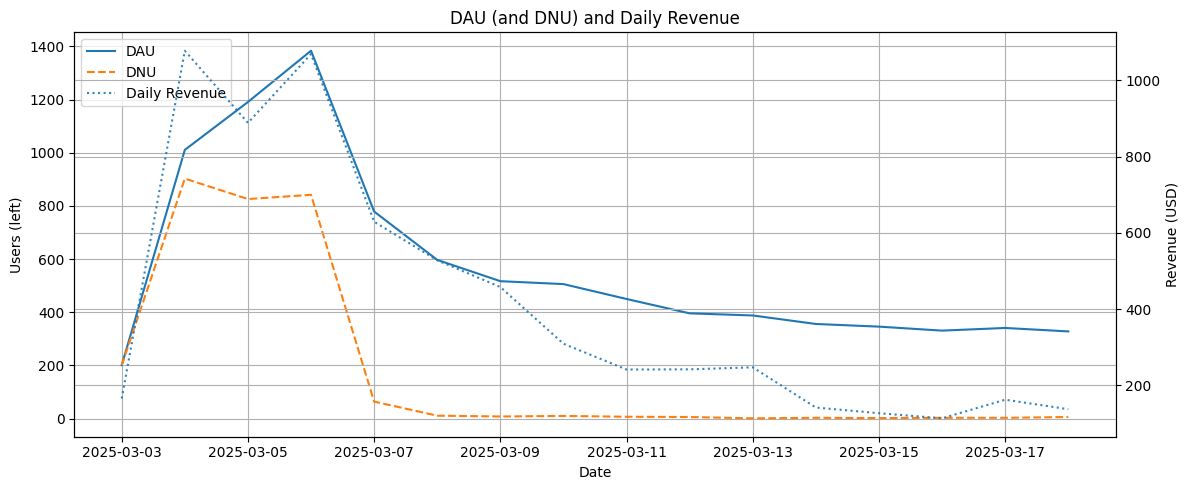

In [48]:
plt.figure(figsize=(12,5))
ax = plt.gca()

ax.plot(dau['event_date'], dau['DAU'], label='DAU')

if not dnu.empty:
    ax.plot(dnu['first_date'], dnu['DNU'], label='DNU', linestyle='--')
ax.set_xlabel('Date')
ax.set_ylabel('Users (left)')

ax2 = ax.twinx()
ax2.plot(kpi_daily['event_date'], kpi_daily['daily_revenue'], label='Daily Revenue', linestyle=':', alpha=0.9)
ax2.set_ylabel('Revenue (USD)')

lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines+lines2, labels+labels2, loc='upper left')
plt.title('DAU (and DNU) and Daily Revenue')
plt.tight_layout()
plt.show()

Chart 2 — ARPDAU & ARPPU trends

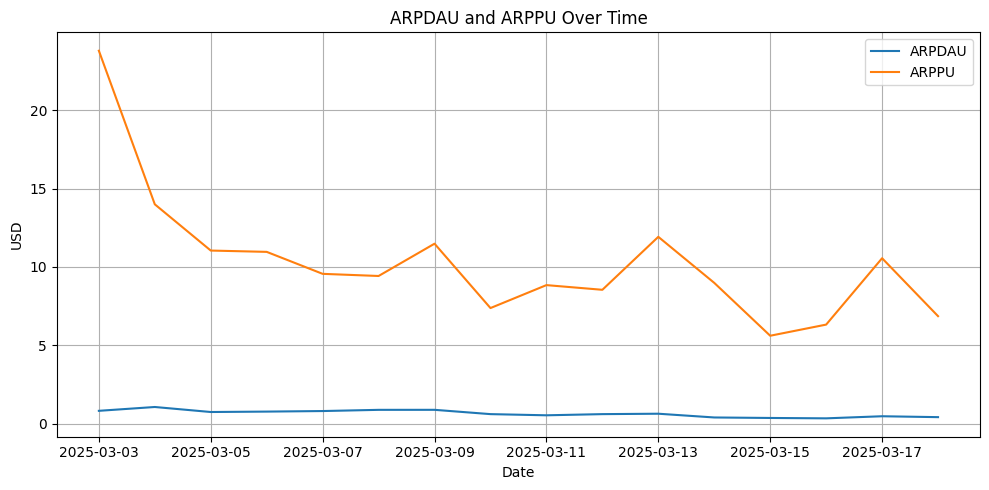

In [48]:
fig, ax = plt.subplots(1,1, figsize=(10,5))
ax.plot(kpi_daily['event_date'], kpi_daily['ARPDAU'], label='ARPDAU')
ax.plot(arppu_df['event_date'], arppu_df['ARPPU'], label='ARPPU')
ax.set_title('ARPDAU and ARPPU Over Time')
ax.set_xlabel('Date')
ax.set_ylabel('USD')
ax.legend()
plt.tight_layout()
plt.show()

In [51]:
sns.set(style="whitegrid", font_scale=1.1)
plt.figure(figsize=(16, 10))

<Figure size 1600x1000 with 0 Axes>

<Figure size 1600x1000 with 0 Axes>

### Retention & LTV for bucket 2 only

C:\Users\pc\AppData\Local\Temp\ipykernel_6284\1085635863.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=kpi_summary, x='exp_variant', y='Retention Rate (%)', palette='Oranges_d')


Text(0, 0.5, 'Retention (%)')

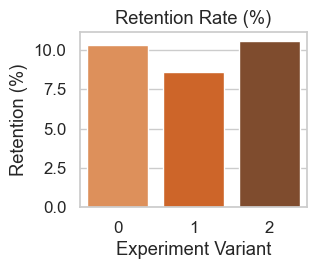

In [55]:
plt.subplot(2, 3, 4)
sns.barplot(data=kpi_summary, x='exp_variant', y='Retention Rate (%)', palette='Oranges_d')
plt.title("Retention Rate (%)")
plt.xlabel("Experiment Variant")
plt.ylabel("Retention (%)")


C:\Users\pc\AppData\Local\Temp\ipykernel_6284\2779758056.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=kpi_summary, x='exp_variant', y='LTV', palette='Reds_d')


Text(0, 0.5, 'LTV ($)')

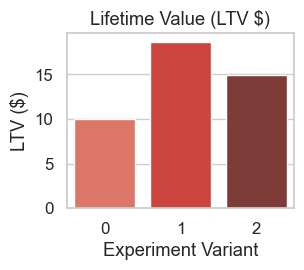

In [56]:
plt.subplot(2, 3, 5)
sns.barplot(data=kpi_summary, x='exp_variant', y='LTV', palette='Reds_d')
plt.title("Lifetime Value (LTV $)")
plt.xlabel("Experiment Variant")
plt.ylabel("LTV ($)")

### KPI summary table

In [59]:
daily_kpis = (kpi_daily
              .merge(dnu.rename(columns={'first_date':'event_date'}), left_on='event_date', right_on='event_date', how='left')
              .merge(arppu_df[['event_date','paying_users','ARPPU']], on='event_date', how='left')
              .fillna(0))
daily_kpis = daily_kpis[['event_date','DAU','DNU','daily_revenue','ARPDAU','paying_users','ARPPU']]
daily_kpis.to_csv(r"C:/Aliaa/work/Fumb/daily_kpis_export.csv", index=False)
daily_kpis

,event_date,DAU,DNU,daily_revenue,ARPDAU,paying_users,ARPPU
0,2025-03-03,201,201,165.222270,0.822001,3,23.799999
1,2025-03-04,1011,903,1077.730669,1.066005,25,13.998800
2,2025-03-05,1191,826,888.399473,0.745927,16,11.048125
3,2025-03-06,1384,842,1068.926203,0.772346,27,10.964444
4,2025-03-07,779,64,629.118647,0.807598,19,9.562231
5,2025-03-08,597,11,527.801381,0.884089,16,9.425625
6,2025-03-09,517,8,457.764544,0.885425,14,11.486429
7,2025-03-10,506,10,308.941110,0.610556,9,7.378889
8,2025-03-11,450,7,241.267593,0.536150,7,8.842857
9,2025-03-12,396,6,241.755533,0.610494,9,8.544444
